# Inspecting the collected data

Run this from `data_process/notebooks/` after `python run_all.py`. Every section reads files written by the pipeline (no new downloads):

1. Provenance: what was downloaded, from where, what failed
2. Catchments and radar domains
3. River level (label source)
4. Flood events
5. Radar rain
6. Soil water (AWRA-L)
7. Master table (`shared/samples.csv`)
8. Candidate B windows
9. Automatic checks (PASS / FAIL)

> **How to read the notes.** Under every table or chart there is a note with four parts: *What it shows*, *What it means*, *Issues and limits*, and (where needed) *Action*. The numbers in the notes come from the run of **17 Oct 2026** (13 catchments, 392 events, 564,708 samples). If you change `config.json` and rerun the pipeline, check the numbers in the outputs; the notes do not update themselves.

In [1]:
import json, sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore', category=DeprecationWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path('..').resolve() if (Path('..') / 'config.json').exists() else Path('.').resolve()
sys.path.insert(0, str(ROOT / 'steps'))
CFG = json.loads((ROOT / 'config.json').read_text())
D, S = ROOT / 'data', ROOT / 'shared'

# colours (fixed order; text stays neutral)
BLUE, ORANGE, AQUA, YELLOW, VIOLET, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#6250d6', '#8a8984'
SPLIT_COL = {'train': BLUE, 'val': ORANGE, 'test': AQUA, 'holdout': YELLOW}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'font.size': 9})
pd.set_option('display.width', 160)

cat = pd.read_csv(S / 'catchments.csv', dtype={'catchment_id': str, 'radar_id': str})
ev = pd.read_csv(S / 'events.csv', dtype={'catchment_id': str}, parse_dates=['onset_utc', 'end_utc'])
samples = pd.read_csv(S / 'samples.csv', dtype={'catchment_id': str}, parse_dates=['issue_utc'])
man = pd.read_csv(D / 'manifest.csv')
P0, P1 = pd.Timestamp(CFG['period']['start_utc']), pd.Timestamp(CFG['period']['end_utc'])
SPLITS = {k: (pd.Timestamp(v[0]), pd.Timestamp(v[1])) for k, v in CFG['split'].items() if k in SPLIT_COL}

def shade_splits(ax):
    for k, (a, b) in SPLITS.items():
        ax.axvspan(a, b, color=SPLIT_COL[k], alpha=0.07 if k != 'holdout' else 0.18, lw=0)

print(f'{len(cat)} catchments, {len(ev)} events, {len(samples):,} samples, {len(man):,} downloads logged')
print('period', P0, '->', P1)

13 catchments, 392 events, 564,708 samples, 5,489 downloads logged
period 2019-06-08 00:00:00+00:00 -> 2026-06-30 23:00:00+00:00


## 1. Provenance

Every request the pipeline made is a row in `data/manifest.csv` (URL, time, HTTP status, size, SHA-256). This is the evidence that the data came from the public sources and was not edited by hand.

In [2]:
man['host'] = man.url.str.extract(r'https?://([^/]+)')
summary = man.groupby(['step', 'host']).agg(requests=('url', 'size'), ok=('status', lambda x: (x == 200).sum()),
                                           not_found=('status', lambda x: (x == 404).sum()),
                                           GB=('bytes', lambda x: round(x.sum() / 1e9, 3)),
                                           first=('retrieved_utc', 'min'), last=('retrieved_utc', 'max'))
summary

,,requests,ok,not_found,GB,first,last
step,host,,,,,,
s01,thredds.nci.org.au,2,2,0,0.002,2026-10-17T09:52:28Z,2026-10-17T09:52:30Z
s02,www.bom.gov.au,117,117,0,0.160,2026-10-17T09:52:31Z,2026-10-17T09:55:32Z
s04,thredds.nci.org.au,5162,5079,83,8.847,2026-10-17T09:55:40Z,2026-10-17T10:32:17Z
s05,thredds.nci.org.au,208,208,0,0.031,2026-10-17T10:40:37Z,2026-10-17T10:42:18Z


**What it shows.**
- Each row groups downloads by pipeline step and host.
- 5,489 requests were made:
  - 2 to read the radar grid definitions;
  - 117 for river level (one per gauge per year);
  - 5,162 daily radar files (8.8 GB);
  - 208 soil subsets.
- 83 radar days returned HTTP 404 (the file does not exist on NCI). Every other request returned data.

**What it means.**
- All data come from two public services: NCI THREDDS (radar, soil) and BoM Water Data Online (river level).
- Each file is listed in `data/manifest.csv` with URL, retrieval time, size and SHA-256 checksum.
- Anyone can rerun the pipeline and verify that the same bytes were used. This is the reproducibility evidence for the report.

**Issues and limits.**
- The checksums prove which bytes were downloaded, not that the provider's data are correct. Provider errors (see the radar artefacts in section 5) still need QC.
- BoM can revise recent provisional river data, so a rerun months later may give slightly different labels for 2025–26.

**Action.**
Quote the source table and the manifest in the report's data section; keep `manifest.csv` with the submission.

       count        min        max
radar                             
28        33 2019-08-22 2026-05-05
66        50 2019-08-06 2026-04-08


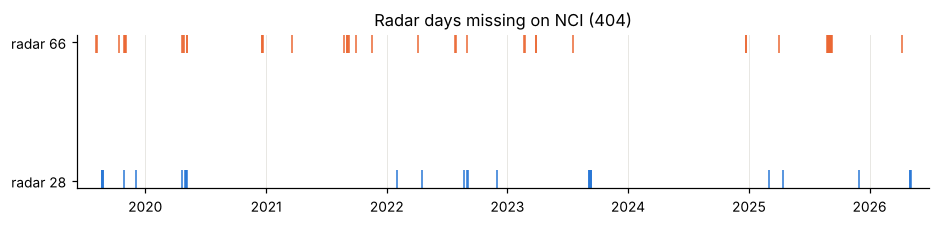

In [3]:
# Radar days that do not exist on NCI (HTTP 404) -> those hours become 'missing', never 0 mm
miss = man[(man.step == 's04') & (man.status == 404)].copy()
miss['radar'] = miss.url.str.extract(r'rainfields3/(\d+)/')[0]
miss['day'] = pd.to_datetime(miss.url.str.extract(r'_(\d{8})\.prcp')[0])
print(miss.groupby('radar').day.agg(['count', 'min', 'max']))
fig, ax = plt.subplots(figsize=(10, 1.8))
for i, (r, g) in enumerate(miss.groupby('radar')):
    ax.plot(g.day, np.full(len(g), i), '|', ms=14, color=[BLUE, ORANGE][i % 2], label=f'radar {r}')
ax.set_yticks(range(miss.radar.nunique()), [f'radar {r}' for r in sorted(miss.radar.unique())])
ax.set_xlim(P0, P1); ax.set_title('Radar days missing on NCI (404)'); ax.grid(axis='y', visible=False)
plt.show()

**What it shows.**
- Each tick is a whole UTC day with no radar file on NCI: 33 days for Grafton (28) and 50 for Mt Stapylton (66).
- Ticks are spread over 2019–2026, with a few short clusters (for example August 2019).

**What it means.**
- A missing day is treated as *missing*, never as zero rain. If it were filled with 0 mm, the model would learn that floods can follow dry hours, which is false.
- Each missing day also removes the next 72 issue times, because their history contains those hours. One missing day therefore costs about 4 days of samples.

**Issues and limits.**
- The gaps are scattered and not tied to one season, so they should not bias any split.
- They do reduce the number of samples (see section 7).
- The pipeline cannot recover these days: NCI does not hold them.

## 2. Catchments and radar domains

Selected by the rule in `config.json` (CAMELS-AUS v2, NSW, 20–500 km², ≥ 99% inside a radar grid). Each catchment uses the nearest radar that covers it.

In [4]:
cat[['catchment_id', 'name', 'area_km2', 'radar_id', 'radar_dist_km', 'mask_cells', 'threshold_m', 'threshold_type']]

,catchment_id,name,area_km2,radar_id,radar_dist_km,mask_cells,threshold_m,threshold_type
0,201001,Oxley River at Eungella,215.0,66,71.1,856,1.848,p99_train
1,203010,Leycester River at Rock Valley,176.1,66,98.9,704,2.631,p99_train
2,203030,Myrtle Creek at Rappville,387.6,28,59.6,1549,3.119,p99_train
3,204017,Bielsdown Creek at Dorrigo No.2 & No.3,74.1,28,84.7,298,1.711,p99_train
4,204025,Orara River at Karangi,134.4,28,74.1,535,2.013,p99_train
5,204030,Aberfoyle River at Aberfoyle,208.7,28,125.6,835,1.212,p99_train
6,204034,Henry River at Newton Boyd,400.3,28,91.4,1607,1.441,p99_train
7,204036,Cataract Creek at Sandy Hill(below Snake Cre,238.7,28,104.4,954,2.184,p99_train
8,204037,Clouds Creek at Clouds Ck,62.9,28,65.6,251,1.480,p99_train
9,204039,Maryland River at D/S Wylie Ck,385.7,66,147.3,1541,1.747,p99_train


**What it shows.**
- The 13 catchments that passed the selection rule (CAMELS-AUS v2, NSW, 20–500 km², ≥ 99% inside one radar grid), out of 65 NSW CAMELS catchments of the right size.
- For each: area, radar used and its distance, number of radar cells inside the catchment, and the flood threshold.

**What it means.**
- Areas of 63–433 km² are the scale where rain turns into a fast river rise: the flash-flood regime we target.
- Every threshold is the 99th percentile of hourly river level in the training years. It marks the top 1% of water levels at that gauge, which is "high flow" rather than an official flood class.

**Issues and limits.**
- **Thresholds are statistical, not impact-based.**
  - Some are low (1.21 m at 204030, 1.27 m at 204056), so part of the positives are moderate rises that would not trigger a warning.
  - Others are high (6.01 m at 204906).
- **The radar is far away for some catchments** (up to 147 km). The radar beam is higher there and may miss low-level rain.
- **Only 13 catchments.** Results may not generalise to other regions.

**Action.**
Where BoM or SES publishes a minor flood level for a gauge, enter it in `config.json → label.manual_thresholds` and rerun step 3 onwards. Report the threshold type used.

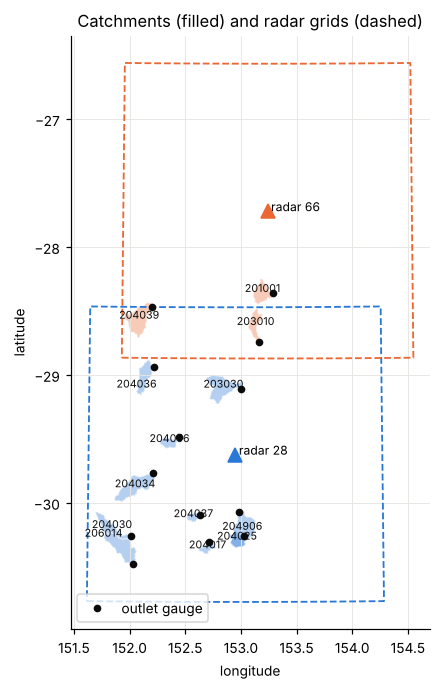

In [5]:
from pyproj import CRS, Transformer
gj = json.loads((S / 'boundaries.geojson').read_text())
fig, ax = plt.subplots(figsize=(7, 7))
for f in gj['features']:
    cid = f['properties']['catchment_id']; r = cat.set_index('catchment_id').radar_id[cid]
    geoms = f['geometry']['coordinates'] if f['geometry']['type'] == 'MultiPolygon' else [f['geometry']['coordinates']]
    for poly in geoms:
        xy = np.array(poly[0]); ax.fill(xy[:, 0], xy[:, 1], color=BLUE if r == '28' else ORANGE, alpha=0.35, lw=0.8, ec='white')
    xy = np.array(geoms[0][0]); ax.annotate(cid, xy.mean(0), fontsize=7, ha='center', color='#0b0b0b')
for rid, col in (('28', BLUE), ('66', ORANGE)):
    g = json.loads((D / 'raw' / 'radar_grid' / f'radar{rid}.json').read_text())
    to_ll = Transformer.from_crs(CRS.from_proj4(g['proj4']), 'EPSG:4326', always_xy=True)
    x0, x1, y0, y1 = min(g['x_km']), max(g['x_km']), min(g['y_km']), max(g['y_km'])
    bx = np.r_[np.linspace(x0, x1, 50), np.full(50, x1), np.linspace(x1, x0, 50), np.full(50, x0)]
    by = np.r_[np.full(50, y0), np.linspace(y0, y1, 50), np.full(50, y1), np.linspace(y1, y0, 50)]
    lon, lat = to_ll.transform(bx, by); ax.plot(lon, lat, color=col, lw=1.2, ls='--')
    c = to_ll.transform(0, 0); ax.plot(*c, marker='^', ms=9, color=col); ax.annotate(f' radar {rid}', c, fontsize=8)
ax.plot(cat.lon, cat.lat, 'o', ms=4, color='#0b0b0b', label='outlet gauge')
ax.set_aspect(1 / np.cos(np.deg2rad(-29.5))); ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title('Catchments (filled) and radar grids (dashed)'); ax.legend(loc='lower left')
plt.show()

**What it shows.**
- Catchment outlines (filled; blue = Grafton radar, orange = Mt Stapylton), outlet gauges (dots), radar sites (triangles) and the edge of each 256 km × 256 km radar grid (dashed).

**What it means.**
- Every catchment lies inside its radar grid. Each one uses the nearest radar that covers it fully.
- The Clarence and Orara catchments (south and centre) use Grafton. The Tweed and Richmond headwaters (201001, 203010) and 204039 use Mt Stapylton.

**Issues and limits.**
- Beam height increases with distance. The farthest catchments (204030, 206014, 204039 at 125–147 km) may have weaker radar estimates.
- The product used merges radar with rain gauges, which partly corrects this, but the error is not zero.

**Action.**
Report distance to radar as a possible source of error. If results are poor for the farthest catchments, this is the first explanation to test.

In [6]:
# Catchment size on the shared metric grid (EPSG:3577): does it fit a 16 km map tile (Candidate A)?
from shapely.geometry import shape
from shapely.ops import transform as _tf
to_alb = Transformer.from_crs('EPSG:4326', 'EPSG:3577', always_xy=True).transform
ext = []
for f in gj['features']:
    x0, y0, x1, y1 = _tf(to_alb, shape(f['geometry'])).bounds
    ext.append({'catchment_id': f['properties']['catchment_id'], 'width_km': round((x1 - x0) / 1e3, 1),
                'height_km': round((y1 - y0) / 1e3, 1)})
ext = pd.DataFrame(ext); ext['fits_16km_tile'] = ext[['width_km', 'height_km']].max(axis=1) <= 16
ext.sort_values('catchment_id')

,catchment_id,width_km,height_km,fits_16km_tile
0,201001,18.5,21.6,False
1,203010,14.1,29.4,False
2,203030,30.3,26.1,False
3,204017,15.3,10.2,True
4,204025,13.1,14.9,True
5,204030,27.3,28.3,False
6,204034,37.4,21.5,False
7,204036,18.8,30.0,False
8,204037,11.6,8.7,True
9,204039,27.0,29.6,False


**What it shows.**
- Width and height of each catchment on the shared metric grid (EPSG:3577, metres), and whether it fits inside Candidate A's 16 km × 16 km tile.

**What it means.**
- **Only 3 of 13 catchments (204017, 204025, 204037) fit in a 16 km tile.**
- The other 10 extend to 18–37 km, so a 16 km tile centred on them shows only part of the catchment. In the 203010 test, the tile covered 69% of the catchment.

**Issues and limits.**
- If A keeps a 16 km tile, its CNN sees only part of the rain that drains to the gauge.
  - This disadvantages A for reasons unrelated to the method.
  - It also breaks the fair comparison with B, which averages rain over the whole catchment.

**Action.**
Decide with member A before training. Options:
1. **Larger tile:** 40 km at 625 m cells keeps 64 × 64.
2. **Crop and resize:** crop to each catchment's bounding box and resize to 64 × 64.
3. **Keep 16 km:** report the coverage of each tile.

In [7]:
static = pd.read_csv(D / 'processed' / 'b' / 'static.csv', dtype={'catchment_id': str}).set_index('catchment_id')
static.describe().T[['min', '50%', 'max']].round(3)

,min,50%,max
catchment_area,62.800,214.800,432.200
elev_mean,156.564,769.914,1303.152
relief,0.189,0.432,0.674
mean_slope_pct,7.420,15.820,28.740
ksat,48.491,180.088,300.000
claya,7.000,21.000,39.000
sanda,29.000,52.300,86.000
solpawhc,73.283,131.422,173.660
lc35_urbanar,0.000,0.000,0.013
prop_forested,0.169,0.868,1.000


**What it shows.**
- Range of the 13 static attributes B uses (taken from CAMELS-AUS).

**What it means.**
- The attributes vary widely: mean elevation 157–1,303 m (coast to tablelands), mean slope 7–29%, forest 17–100%, mean rainfall 2.1–4.8 mm/day.
- These differences explain why the same rain floods one catchment and not another. They let one model serve all catchments.

**Issues and limits.**
- **`lc35_urbanar` (urban share) is almost 0 everywhere.** It carries no information here.
- **13 catchments is a small number.** Each catchment's 13 numbers are close to a unique "fingerprint", so the model could learn "catchment X floods often" instead of physics.
- **The attributes are summaries from CAMELS-AUS**, not our own layers. Their sources and dates are given in the CAMELS-AUS paper.

**Action.**
- Consider dropping `lc35_urbanar`.
- Use regularisation (dropout, weight decay).
- Add one leave-catchment-out test, so the model is also evaluated on catchments it never saw.

## 3. River level (label source)

BoM series `DMQaQc.Merged.AsStored.1` (15-min readings) turned into the **maximum level in each UTC hour (h−1, h]**. Gaps here make labels unknown, so those issue times are dropped.

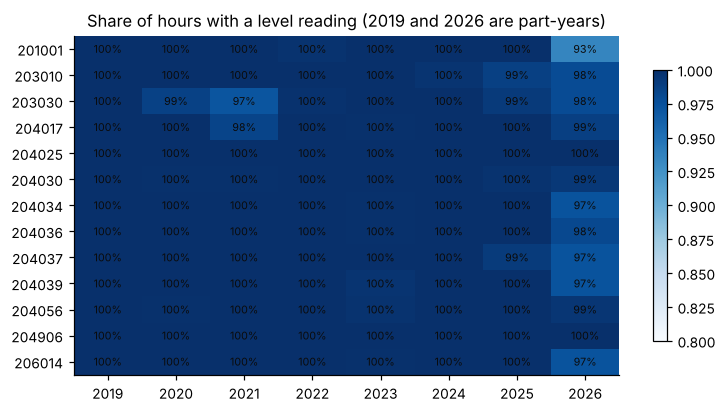

In [8]:
lv = {c: pd.read_csv(D / 'interim' / 'levels' / f'{c}.csv', index_col=0, parse_dates=True).level_max_m for c in cat.catchment_id}
hours = pd.date_range(P0, P1, freq='1h', tz='UTC')
cov = pd.DataFrame({c: s.reindex(hours).notna().groupby(hours.year).mean() for c, s in lv.items()}).T
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(cov.values, aspect='auto', cmap='Blues', vmin=0.8, vmax=1)
ax.set_yticks(range(len(cov)), cov.index); ax.set_xticks(range(cov.shape[1]), cov.columns); ax.grid(False)
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        ax.text(j, i, f'{cov.values[i, j]:.0%}', ha='center', va='center', fontsize=7, color='#0b0b0b')
ax.set_title('Share of hours with a level reading (2019 and 2026 are part-years)'); plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

**What it shows.**
- Share of hours with a river-level reading, by gauge and year.

**What it means.**
- River level is 97–100% complete in every year.
- Missing level hours make the label unknown, so those issue times are dropped.
- Because so few hours are missing, labels are **not** the limiting factor. Radar is (section 7).

**Issues and limits.**
- 2019 and 2026 are part-years.
- The lower 2026 values (93–99%) reflect recent data still being processed by BoM. These may be revised later.

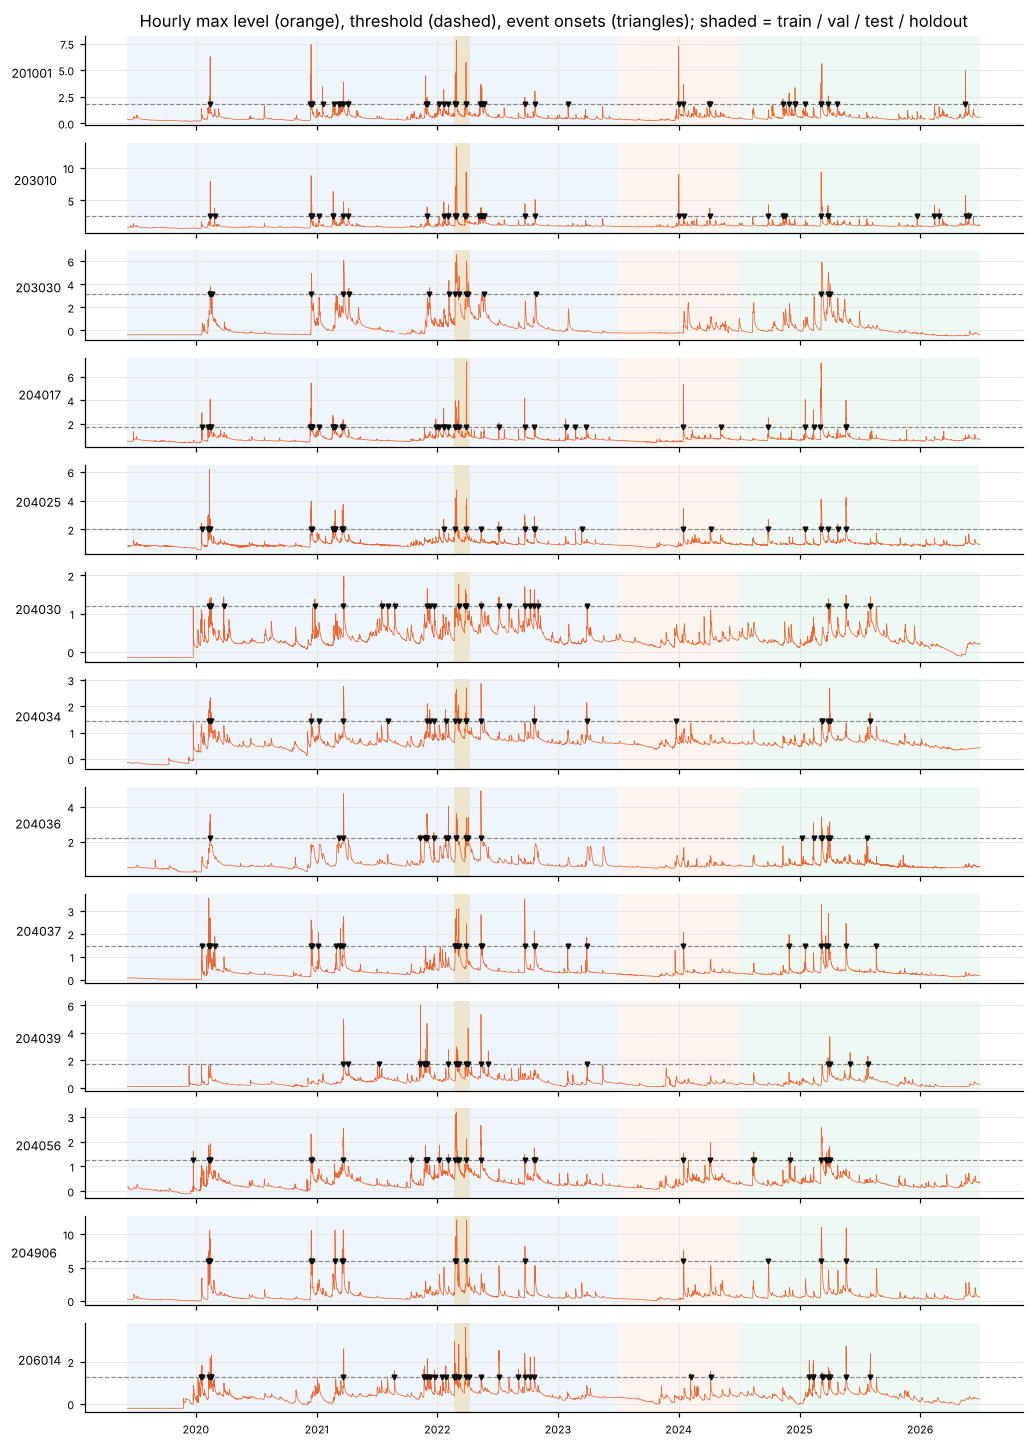

In [9]:
fig, axes = plt.subplots(len(cat), 1, figsize=(11, 1.25 * len(cat)), sharex=True)
for ax, c in zip(axes, cat.itertuples()):
    s = lv[c.catchment_id]
    shade_splits(ax)
    ax.plot(s.index, s.values, lw=0.5, color=ORANGE)
    ax.axhline(float(c.threshold_m), color=GREY, ls='--', lw=0.8)
    on = ev[ev.catchment_id == c.catchment_id].onset_utc
    ax.plot(on, np.full(len(on), float(c.threshold_m)), 'v', ms=3, color='#0b0b0b')
    ax.set_ylabel(c.catchment_id, rotation=0, ha='right', fontsize=8); ax.tick_params(labelsize=7)
axes[0].set_title('Hourly max level (orange), threshold (dashed), event onsets (triangles); shaded = train / val / test / holdout')
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
plt.show()

**What it shows.**
- Hourly maximum river level for each gauge (orange), its threshold (dashed) and every flood onset (triangles), over the split periods: blue = train, orange = val, green = test, sand = holdout.

**What it means.**
- Flood activity clusters in the wet years 2020–2022 and in early 2025. 2019 (drought) and 2023 are quiet.
- Most gauges respond to the same storms, because one weather system affects the whole region. This is why the split is by time and not by event or catchment.

**Issues and limits.**
- **The validation year (Jul 2023 – Jun 2024) has very few crossings.** That is the climate, not the pipeline, but it makes validation weak.
- **Some gauges flat-line in the 2019 drought** (for example 204030 at −0.15 m until late December 2019), then jump when flow returns.
- **A few show step changes** that may be datum or sensor changes.
- None of these create false onsets: the jumps stay below the thresholds.

**Action.**
Mention possible gauge datum changes and drought flat-lines as a data limitation in the report.

## 4. Flood events

An event starts at the first hour above the threshold after ≥ 24 h below, and ends at the first hour back below. Thresholds are the p99 of hourly level in **train years only** unless an official minor level is entered in `config.json`.

In [10]:
import sys; sys.path.insert(0, str(ROOT / 'steps'))
from common import split_of
ev['split'] = split_of(pd.DatetimeIndex(ev.onset_utc))
ev['duration_h'] = (ev.end_utc - ev.onset_utc) / pd.Timedelta(hours=1)
tab = ev.pivot_table(index='catchment_id', columns='split', values='onset_utc', aggfunc='count', fill_value=0)
tab['total'] = tab.sum(axis=1); tab.loc['ALL'] = tab.sum()
tab

split,holdout,test,train,val,total
catchment_id,,,,,
201001,5,10,26,4,45
203010,6,11,22,3,42
203030,4,3,10,0,17
204017,4,6,25,2,37
204025,2,6,22,2,32
204030,4,3,20,0,27
204034,4,5,14,1,24
204036,5,7,11,0,23
204037,5,7,19,1,32


**What it shows.**
- Number of flood onsets per gauge and split: 392 in total (train 231, val 18, test 84, holdout 59).

**What it means.**
- Training has enough events per catchment (9–26) for the model to learn the rain–flood relation.
- The holdout contains 3–7 onsets per gauge from one extreme period. That makes it a strong stress test.

**Issues and limits.**
- **Validation has only 18 events, and 4 catchments have none.**
  - Choosing an alert threshold or the best epoch on so few events is unreliable.
  - It is easy to over-fit to one storm.

**Action.**
Either:
- tune with time-based cross-validation inside the training years (for example leave-one-water-year-out), **or**
- keep validation, but report its uncertainty (bootstrap by event).

In [11]:
# How many upward threshold crossings become onsets for different 'hours below' settings
rows = []
for c in cat.itertuples():
    a = (lv[c.catchment_id].dropna() > float(c.threshold_m)).astype(int).values
    up = np.flatnonzero((a[1:] == 1) & (a[:-1] == 0)) + 1
    below = np.zeros(len(a), int); run_ = 0
    for i, v in enumerate(a): below[i] = run_; run_ = 0 if v else run_ + 1
    rows.append({'catchment_id': c.catchment_id, 'crossings': len(up), **{f'onsets_if_{k}h': int((below[up] >= k).sum()) for k in (6, 12, 24)}})
aud = pd.DataFrame(rows); aud.loc[len(aud)] = ['ALL'] + aud.iloc[:, 1:].sum().tolist()
print('config onset_min_hours_below =', CFG['label']['onset_min_hours_below'], '(crossings below the setting are merged into the previous event)')
aud.tail(1)

config onset_min_hours_below = 6 (crossings below the setting are merged into the previous event)


,catchment_id,crossings,onsets_if_6h,onsets_if_12h,onsets_if_24h
13,ALL,434,390,362,337


**What it shows.**
- How many of the 434 upward crossings of the threshold count as new floods, depending on how long the river must first stay below the threshold.

**What it means.**
- With 6 h (the current setting), 390 crossings become onsets. The other 44 come back up too quickly and are merged into the previous flood: they are excluded, never labelled "no flood".
- The old 24 h rule would have dropped 97 crossings, including the main Lismore peak of 27 Feb 2022 at 203010.

**Issues and limits.**
- The number of positives depends on this choice. 6 h is a judgement: long enough to separate two storms, short enough to keep a second peak.
- It is not taken from a standard. Any value in 6–12 h is defensible.

**Action.**
State the 6 h rule and the merging rule in the label definition of the report.

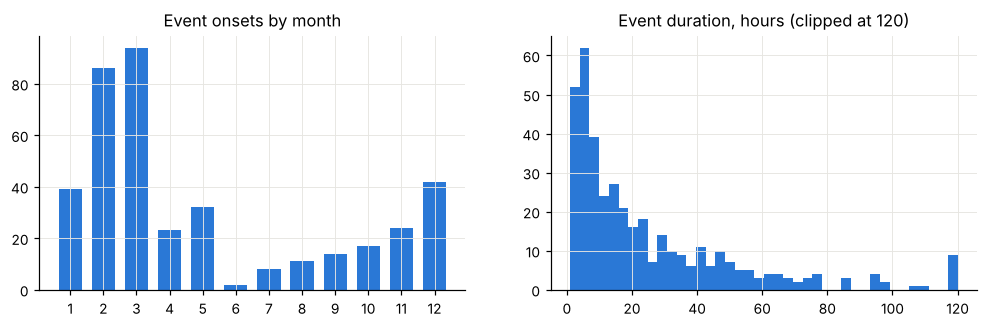

count    392.0
mean      25.4
std       30.1
min        1.0
25%        6.0
50%       14.0
75%       34.2
max      216.0
Name: duration_h, dtype: float64


In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3))
m = ev.onset_utc.dt.month.value_counts().reindex(range(1, 13), fill_value=0)
a1.bar(m.index, m.values, color=BLUE, width=0.7); a1.set_xticks(range(1, 13)); a1.set_title('Event onsets by month')
a2.hist(ev.duration_h.clip(upper=120), bins=40, color=BLUE); a2.set_title('Event duration, hours (clipped at 120)')
plt.show()
print(ev.duration_h.describe().round(1))

**What it shows.**
- Left: onsets by calendar month. Right: how long the river stays above threshold.

**What it means.**
- **Strong seasonality.**
  - 81% of onsets fall in December–May, and 46% in February–March alone.
  - June–September has only 9%.
  - This is the summer–autumn wet season of northern NSW.
- **Events are short.**
  - Median 14 h above threshold; 29% last 6 h or less.
  - That is consistent with fast-responding catchments and a 6 h forecast horizon.

**Issues and limits.**
- **Few winter events** means the model learns mostly summer storms and may be weaker on winter or east-coast-low events.
- **A few very long events** (up to 9 days) come from the 2022 floods; their issue times are mostly excluded as "already in flood".

**Action.**
Report performance by season, or state that results mainly describe the wet season.

## 5. Radar rain

Rainfields3 `prcp-m15` (merged gauge/radar, 15-min, mm). An hour is **good** (`common.radar_good`) when all 4 scans exist, ≥ 90% of the catchment has data, no cell carries the fill code (raw 65535 = 3276.7 mm), and the catchment maximum is not *stuck* (same value ≥ 6 h in a row while ≥ 20 mm/h). One bad hour removes every issue time whose 72-h history contains it (up to 72 samples).

In [13]:
rad = pd.concat([pd.read_csv(D / 'interim' / 'radar' / f'radar{r}_hourly.csv', dtype={'catchment_id': str})
                 for r in sorted(cat.radar_id.unique())])
rad['t'] = pd.to_datetime(rad.hour_end_utc, utc=True)
R = CFG['radar']
from common import radar_good
rad = rad.sort_values(['catchment_id', 't'])
rad['good'] = pd.concat([radar_good(g) for _, g in rad.groupby('catchment_id', sort=False)])
rad['fill_code'] = rad.rain_max >= R['qc_max_mm_per_hour']
run = rad.groupby('catchment_id', group_keys=False).rain_max.apply(lambda m: m.groupby((m != m.shift()).cumsum()).transform('size'))
rad['stuck'] = (run >= R['qc_stuck_hours']) & (rad.rain_max >= R['qc_stuck_min_mm'])
q = []
for c in cat.catchment_id:
    g = rad[rad.catchment_id == c].set_index('t').reindex(hours)
    q.append(dict(catchment_id=c, hours_expected=len(hours), present=int(g.n15.notna().sum()),
                  scans_lt4=int((g.n15 < 4).sum()), low_coverage=int((g.coverage < R['min_coverage']).sum()),
                  fill_code=int(g.fill_code.fillna(False).astype(bool).sum()), stuck=int(g.stuck.fillna(False).astype(bool).sum()),
                  good_share=round(float(g.good.astype(float).fillna(0).mean()), 4)))
pd.DataFrame(q)

,catchment_id,hours_expected,present,scans_lt4,low_coverage,fill_code,stuck,good_share
0,201001,61920,60061,481,7,0,0,0.9622
1,203010,61920,60061,481,6,0,0,0.9622
2,203030,61920,60582,533,14,0,0,0.9696
3,204017,61920,60582,533,27,1,0,0.9694
4,204025,61920,60582,533,23,1,0,0.9695
5,204030,61920,60582,533,14,0,0,0.9696
6,204034,61920,60582,533,12,0,0,0.9696
7,204036,61920,60582,533,6,0,0,0.9697
8,204037,61920,60582,533,7,0,0,0.9697
9,204039,61920,60061,481,1,0,0,0.9622


**What it shows.**
- Radar quality per catchment over the 61,920 study hours:
  - hours present;
  - hours with fewer than 4 scans;
  - hours with low coverage;
  - hours with the fill code;
  - hours with a stuck maximum;
  - the final share of usable ("good") hours.

**What it means.**
- 96–97% of hours are usable at every catchment. The losses come from:
  - **Missing days:** about 1,340 hours for Grafton catchments and 1,860 for Mt Stapylton.
  - **Partial hours:** about 500 hours with 1–3 scans.
  - **Fill code:** 6 hours where the stored value 65535 would have been read as 3,277 mm.
  - **Stuck maximum:** 28 hours at 204056 (April 2024).

**Issues and limits.**
- Losses look small per hour, but each bad hour blocks the 72 issue times that contain it. That is why about 28% of samples are dropped (section 7).
- The QC rules catch obvious errors only. Plausible-looking but wrong rain is not caught (see the plausibility table below).

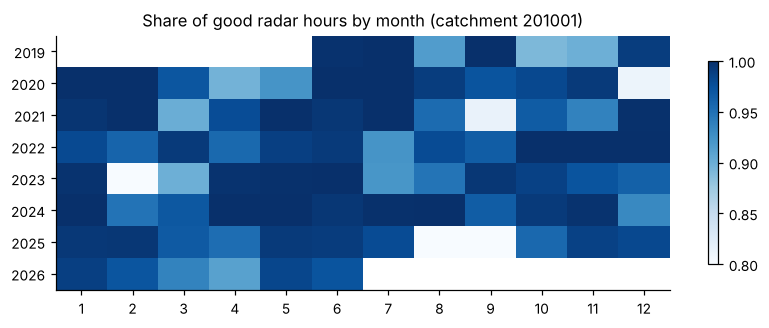

In [14]:
g = rad[rad.catchment_id == cat.catchment_id.iloc[0]].set_index('t').reindex(hours)
good_m = g.good.astype(float).fillna(0).groupby([hours.year, hours.month]).mean().unstack()
fig, ax = plt.subplots(figsize=(9, 3))
im = ax.imshow(good_m.values, aspect='auto', cmap='Blues', vmin=0.8, vmax=1)
ax.set_yticks(range(len(good_m)), good_m.index); ax.set_xticks(range(12), range(1, 13)); ax.grid(False)
ax.set_title(f'Share of good radar hours by month (catchment {cat.catchment_id.iloc[0]})'); plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

**What it shows.**
- Share of usable radar hours per month for 201001 (Mt Stapylton radar). Darker = more complete.

**What it means.**
- Most months are 95–100% usable.
- The pale months (for example December 2020, September 2021, February 2023, August–September 2025) are radar outages. Empty cells are outside the study period.

**Issues and limits.**
- Outages fall in different seasons and years, so no split loses a whole wet season.
- February 2023 is a wet-season month with low availability, so a few possible events there have no samples.

In [15]:
# Annual rain totals from radar (good hours only) - a plausibility check against known wet years (2021-22 La Nina)
tot = rad[rad.good].assign(year=lambda d: d.t.dt.year).pivot_table(index='catchment_id', columns='year', values='rain_mean', aggfunc='sum').round(0)
tot

year,2019,2020,2021,2022,2023,2024,2025,2026
catchment_id,,,,,,,,
201001,300.0,1623.0,1754.0,2515.0,1000.0,1863.0,2089.0,980.0
203010,301.0,1105.0,1213.0,1899.0,710.0,1280.0,1559.0,689.0
203030,233.0,859.0,1141.0,1157.0,515.0,867.0,1156.0,341.0
204017,423.0,1772.0,1723.0,1983.0,928.0,1427.0,2021.0,463.0
204025,398.0,1961.0,1884.0,2086.0,1001.0,1680.0,2192.0,584.0
204030,122.0,745.0,617.0,688.0,636.0,749.0,883.0,215.0
204034,236.0,935.0,943.0,956.0,767.0,911.0,1171.0,235.0
204036,181.0,715.0,1004.0,838.0,635.0,769.0,981.0,224.0
204037,321.0,1723.0,1505.0,1461.0,878.0,2531.0,1689.0,363.0


**What it shows.**
- Total radar rain per catchment and calendar year (usable hours only). 2019 and 2026 are part-years.

**What it means.**
- **The totals follow known climate:**
  - dry 2019 (drought);
  - wet 2020–2022 (La Niña), with the highest totals in 2022 at the coastal catchments (201001: 2,515 mm);
  - dry 2023;
  - wet again in 2025.
- **Coastal and escarpment catchments are about twice as wet as tableland ones**, matching their mean rainfall (`p_mean`). So the radar input is broadly realistic.

**Issues and limits.**
- **Two values look wrong:**
  - 204037: 2,531 mm in 2024;
  - 204056: 1,788 mm in 2024, even after the April exclusion.
- Neighbouring catchments do not show this. See the next table.
- Radar totals also miss a few % in years with outages.

In [16]:
# Plausibility: wettest 72 h per catchment (good hours) and the river peak in the following 24 h.
# Very large rain with a small river response points to a radar artefact -> review, then list it in config radar.qc_exclude
rows = []
for c in cat.catchment_id:
    g = rad[(rad.catchment_id == c)].set_index('t')
    r72 = g.rain_mean.where(g.good, 0).asfreq('h').fillna(0).rolling(72).sum()
    t = r72.idxmax(); pk = lv[c][t - pd.Timedelta(hours=72): t + pd.Timedelta(hours=24)].max()
    rows.append({'catchment_id': c, 'max_72h_rain_mm': round(r72.max()), 'ending': t.date(), 'river_peak_m': round(pk, 2),
                 'threshold_m': cat.set_index('catchment_id').threshold_m[c]})
print('manual exclusions in config:', [(x['catchment_id'], x['start_utc'][:10], x['end_utc'][:10]) for x in R.get('qc_exclude', [])])
pd.DataFrame(rows).sort_values('max_72h_rain_mm', ascending=False)

manual exclusions in config: [('204056', '2024-04-08', '2024-04-21')]


,catchment_id,max_72h_rain_mm,ending,river_peak_m,threshold_m
10,204056,562,2024-07-02,0.40,1.269
8,204037,456,2024-04-16,0.37,1.480
1,203010,453,2022-02-28,13.16,2.631
0,201001,451,2022-02-28,7.83,1.848
3,204017,359,2025-03-08,7.16,1.711
11,204906,330,2025-03-09,11.07,6.013
4,204025,329,2025-03-09,4.10,2.013
2,203030,222,2022-02-28,6.57,3.119
9,204039,117,2020-12-04,0.72,1.747
6,204034,102,2020-12-05,1.04,1.441


**What it shows.**
- For each catchment, the wettest 72 h on record (usable hours) and the highest river level from 72 h before to 24 h after.

**What it means.**
- For real storms, very heavy rain gives a large river response:
  - 203010: 453 mm → 13.2 m;
  - 201001: 451 mm → 7.8 m.
- This table tests whether rain and river agree. It is a simple physical check on the radar.

**Issues and limits.**
- **Two rows disagree strongly:**
  - 204056: 562 mm ending 2 July 2024, river 0.40 m;
  - 204037: 456 mm ending 16 April 2024, river 0.37 m.
- Rain like this on small, steep catchments cannot leave the river at baseflow. These are almost certainly radar or gauge-merge artefacts, like the April 2024 period already excluded at 204056.
- **If kept, they teach the model that extreme rain can produce no flood.**

**Action.**
Team to confirm; then add both periods to `config.json → radar.qc_exclude` with this table as the reason, and rerun steps 6–8.

catchment_id         hour_end_utc  rain_mean  rain_max
      204017 2020-09-05T05:00:00Z     11.456   3279.70
      204025 2020-09-05T08:00:00Z     98.757   3276.75
      204906 2020-09-05T07:00:00Z      9.432   3282.50
      204906 2020-09-05T08:00:00Z     88.022   3276.75
      204906 2020-09-10T04:00:00Z      6.285   3277.75
      204906 2020-09-11T12:00:00Z      4.312   3276.70


river level max in this window: 1.96 m; threshold 1.269 m


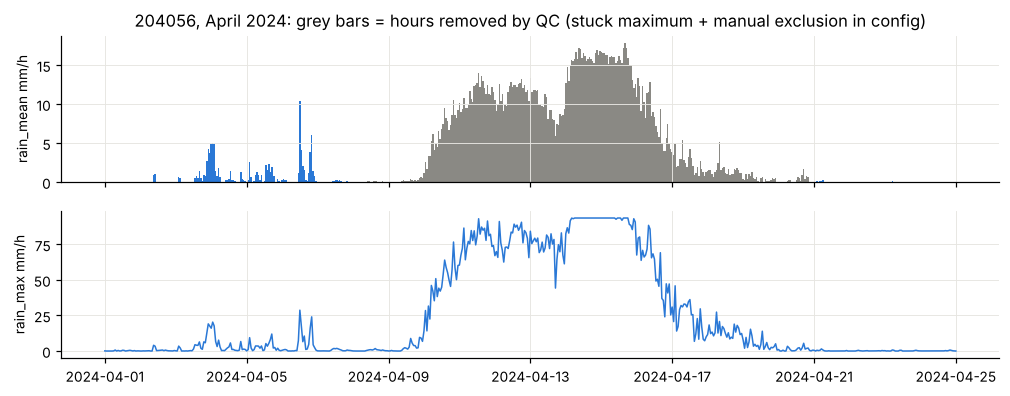

In [17]:
# What the QC removes: the stuck artefact at 204056 in April 2024 and the fill-code hours
print(rad[rad.fill_code][['catchment_id', 'hour_end_utc', 'rain_mean', 'rain_max']].to_string(index=False))
x = rad[(rad.catchment_id == '204056') & rad.t.between(pd.Timestamp('2024-04-01', tz='UTC'), pd.Timestamp('2024-04-25', tz='UTC'))]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 3.8), sharex=True)
a1.bar(x.t, x.rain_mean, width=1 / 24, color=np.where(x.good, BLUE, GREY)); a1.set_ylabel('rain_mean mm/h')
a1.set_title('204056, April 2024: grey bars = hours removed by QC (stuck maximum + manual exclusion in config)')
a2.plot(x.t, x.rain_max, color=BLUE, lw=1); a2.set_ylabel('rain_max mm/h')
s_ = lv['204056'][x.t.min():x.t.max()]
print('river level max in this window:', round(s_.max(), 2), 'm; threshold', cat.set_index('catchment_id').threshold_m['204056'], 'm')
plt.show()

**What it shows.**
- Top: catchment rain at 204056 in April 2024 (grey = removed by QC). Bottom: the catchment maximum.
- Above the chart: the six hours where the fill code appeared.

**What it means.**
- From about 9 to 17 April, rain stays at 10–17 mm/h for days, and the maximum is stuck at exactly 93.6 mm/h. Meanwhile the river never exceeds 1.96 m.
- The automatic "stuck" rule removes only the flat plateau (28 h). The manual exclusion in `config.json` removes the whole period.
- The fill-code values (about 3,277 mm/h in September 2020) are a storage code, not rain, and are now treated as missing.

**Issues and limits.**
- Manual exclusions need human judgement. Each must carry a written reason in the config, and the report should list them.

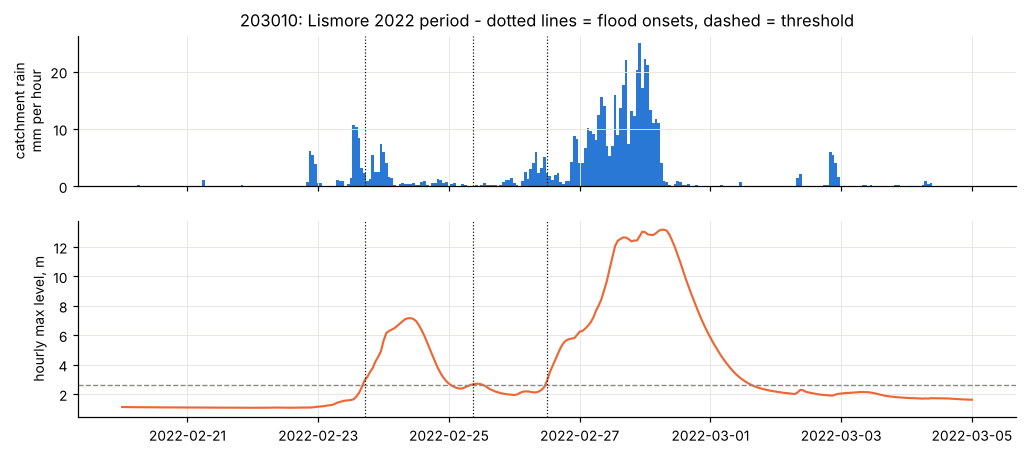

In [18]:
# One event in detail: rain (top) and river level (bottom) share the time axis, not a y-axis
cid = cat.catchment_id.iloc[1]; a, b = pd.Timestamp('2022-02-20', tz='UTC'), pd.Timestamp('2022-03-05', tz='UTC')
r = rad[(rad.catchment_id == cid) & rad.t.between(a, b)]
s = lv[cid][a:b]; thr = float(cat.set_index('catchment_id').threshold_m[cid])
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True, gridspec_kw={'height_ratios': [1, 1.3]})
a1.bar(r.t, r.rain_mean, width=1 / 24, color=BLUE); a1.set_ylabel('catchment rain\nmm per hour')
a2.plot(s.index, s.values, color=ORANGE, lw=1.4); a2.axhline(thr, color=GREY, ls='--', lw=0.9)
for o in ev[(ev.catchment_id == cid) & ev.onset_utc.between(a, b)].onset_utc:
    for ax in (a1, a2): ax.axvline(o, color='#0b0b0b', lw=0.8, ls=':')
a2.set_ylabel('hourly max level, m'); a1.set_title(f'{cid}: Lismore 2022 period - dotted lines = flood onsets, dashed = threshold')
plt.show()

**What it shows.**
- Leycester River at Rock Valley (203010) during the Lismore floods: hourly catchment rain (top) and river level (bottom), with flood onsets (dotted) and threshold (dashed).

**What it means.**
- Rain and river line up as expected.
  - A first burst on 23 February lifts the river above threshold. It drops back, then rises again.
  - The main burst (up to about 25 mm/h, about 450 mm in the 72 h to 28 February) drives the river to 13.2 m, roughly 8 h after the heaviest rain.
- Three onsets are marked: 23 February, a short rise on 25 February, and the main rise on 26 February. The later two would have been missed under the old 24 h rule.
- A lag of a few to ~8 h is why a 6 h forecast is possible: much of the rain that causes the peak has already fallen at the issue time.

**Issues and limits.**
- Before the main peak, the river is still above or near threshold for long periods. Many issue times are excluded as "already in flood", so the most dramatic hours are not scored.

## 6. Soil water (AWRA-L v7)

Daily catchment mean of `s0` (0–0.1 m) and `ss` (0.1–1 m), in mm. In B's table every hour uses the value of the local day **before** that hour's date.

             soil_upper_mm              soil_lower_mm              
                       min median   max           min median    max
catchment_id                                                       
201001                 0.0    2.2  29.7           6.3  123.5  178.7
203010                 0.0    2.1  30.5           7.7  131.5  179.5
203030                 0.0    1.0  20.3           2.9   79.5  181.1
204017                 0.1    3.3  30.0          11.4  151.5  175.3
204025                 0.0    1.4  23.2           6.1  128.7  181.8
204030                 0.0    1.2  12.8           1.8   80.0  179.1
204034                 0.0    0.9  10.7           2.8   74.7  181.9
204036                 0.0    0.8  12.2           3.4   67.0  182.0
204037                 0.0    1.5  20.1           8.0  133.4  180.1
204039                 0.0    0.7  12.7           3.4   59.8  173.2
204056                 0.0    1.0  15.7           9.3  103.3  181.4
204906                 0.0    1.2  19.5         

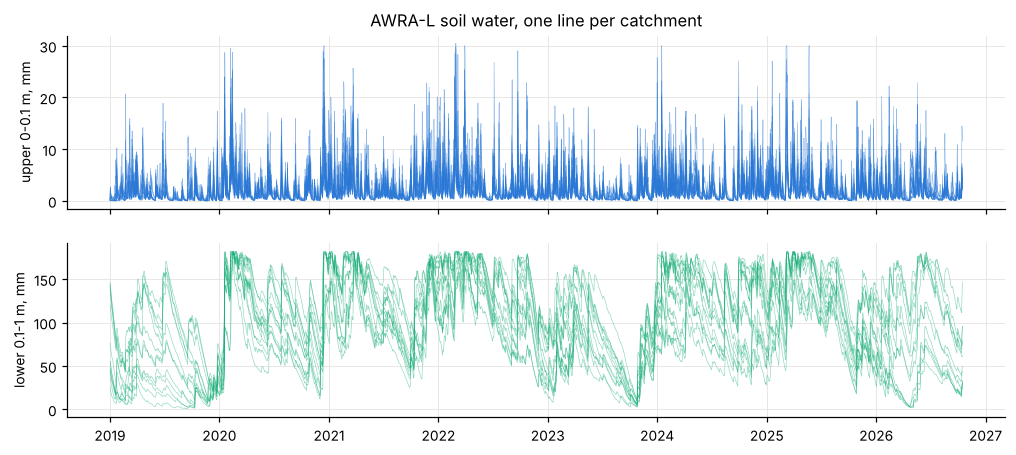

In [19]:
soil = pd.read_csv(D / 'interim' / 'soil_daily.csv', dtype={'catchment_id': str}, parse_dates=['date'])
print(soil.groupby('catchment_id')[['soil_upper_mm', 'soil_lower_mm']].agg(['min', 'median', 'max']).round(1))
print('missing values:', soil[['soil_upper_mm', 'soil_lower_mm']].isna().sum().to_dict())
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
for c, g in soil.groupby('catchment_id'):
    a1.plot(g.date, g.soil_upper_mm, lw=0.4, color=BLUE, alpha=0.5); a2.plot(g.date, g.soil_lower_mm, lw=0.4, color=AQUA, alpha=0.5)
a1.set_ylabel('upper 0-0.1 m, mm'); a2.set_ylabel('lower 0.1-1 m, mm'); a1.set_title('AWRA-L soil water, one line per catchment')
plt.show()

**What it shows.**
- AWRA-L modelled soil water per catchment: upper layer (0–0.1 m) and lower layer (0.1–1 m), in mm, one line per catchment.

**What it means.**
- **The upper layer reacts within a day** to rain (spikes to about 30 mm), then dries quickly.
- **The lower layer is the "memory" of the season:**
  - near empty in the 2019 drought and late 2023;
  - near full (about 180 mm) through 2020–2022.
- This is the antecedent wetness signal: the same storm floods when the lower layer is full and soaks in when it is dry. An LSTM can combine it with the rain history.

**Issues and limits.**
- **These are model estimates (AWRA-L), not measurements.** They are daily at about 5 km, coarser than the catchments.
- **Soil is a daily step in the hourly series.** Each hour uses the previous local day, so no future information is used. But soil water lags rain by up to a day within a storm.
- **No gaps.** The series runs past June 2026 only because whole years were downloaded; the extra days are not used.

## 7. Master table (`shared/samples.csv`)

One row per (catchment, issue hour) that can be scored. Columns: `catchment_id, issue_utc, label, split`.

In [20]:
t = samples.groupby(['split', 'label']).size().unstack(fill_value=0)
t['positive_rate_%'] = (100 * t[1] / t.sum(axis=1)).round(2)
t

label,0,1,positive_rate_%
split,,,
holdout,11552,334,2.81
test,103403,299,0.29
train,368606,1088,0.29
val,79354,72,0.09


**What it shows.**
- Rows of the master table by split and label, with the share of positives.

**What it means.**
- **The task is highly imbalanced.**
  - Train has 1,088 positives in 369,694 hours (0.29%).
  - Test has the same rate (0.29%), so the test reflects the training conditions.
  - Validation has 0.09% (a dry year).
  - Holdout has 2.8% (an extreme flood period).

**Issues and limits.**
- **Accuracy is meaningless here.** Predicting "no flood" every hour scores 99.7%.
- **Rebalancing distorts probabilities.** A class-weighted loss or undersampling makes the predicted probabilities too high.
- **Holdout and test scores are not directly comparable**, because the holdout base rate is ten times higher.

**Action.**
- Use a class-weighted loss or undersample negatives **in training only**.
- Evaluate with precision–recall (PR-AUC), recall and false-alarm ratio at the chosen alert threshold, and the Brier score.
- Calibrate probabilities on validation data.

In [21]:
fs = pd.read_csv(D / 'interim' / 'samples_filter_stats.csv', dtype={'catchment_id': str})
fs['kept_%'] = (100 * fs.kept / fs.candidate).round(1)
fs

,catchment_id,candidate,radar_gap,level_gap,in_flood,kept,kept_%
0,201001,61843,16634,349,797,43979,71.1
1,203010,61843,16623,323,801,44042,71.2
2,203030,61843,17644,717,1062,42469,68.7
3,204017,61843,17986,243,865,42740,69.1
4,204025,61843,17829,7,780,43110,69.7
5,204030,61843,17229,110,527,43813,70.8
6,204034,61843,17423,173,727,43482,70.3
7,204036,61843,17218,123,652,43723,70.7
8,204037,61843,17226,291,786,43571,70.5
9,204039,61843,16623,202,619,44206,71.5


**What it shows.**
- For each catchment: candidate issue hours, and how many were dropped for each reason (radar gap, level gap, already in flood), with the share kept.

**What it means.**
- About 70% of candidate hours are kept at every catchment.
- Radar gaps remove about 17,000 hours per catchment (28%). Level gaps and "in flood" remove at most about 1,000.

**Issues and limits.**
- The radar loss is large because one bad hour blocks 72 issue times.
- Isolated partial hours (3 of 4 scans) are the main cause. They cost far more samples than their number suggests.

**Action.**
See the sensitivity result below.

In [22]:
# Sensitivity: how many more issue times survive if an hour with 3 of 4 scans is accepted?
hist = CFG['time']['history_hours']
def kept_share(min_scans):
    out = []
    for c in cat.catchment_id:
        g = rad[rad.catchment_id == c].set_index('t').reindex(hours)
        ok = (((g.n15 >= min_scans) & (g.coverage >= R['min_coverage'])) & g.good.astype(float).fillna(0).astype(bool) | ((g.n15 == 3) & (min_scans == 3) & ~g.fill_code.fillna(False).astype(bool) & ~g.stuck.fillna(False).astype(bool) & (g.coverage >= R['min_coverage']))).astype(int)
        out.append(ok.rolling(hist).min().eq(1).mean())
    return np.mean(out)
for k in (4, 3):
    print(f'min scans per hour = {k}: share of hours with a complete 72-h history = {kept_share(k):.1%}')

min scans per hour = 4: share of hours with a complete 72-h history = 71.9%


min scans per hour = 3: share of hours with a complete 72-h history = 84.4%


**What it shows.**
- Share of hours with a complete 72 h radar history, if an hour needs 4 of 4 scans (current) or 3 of 4.

**What it means.**
- Accepting 3 of 4 scans raises usable issue times from 71.9% to 84.4%: about 12 percentage points, on the order of 100,000 more samples across the 13 catchments.

**Issues and limits.**
- An hour with one missing 15-min scan underestimates rain unless corrected, for example by scaling by 4/3. That adds a little noise but much more data.
- This is a trade-off for the team, not an error.

**Action.**
If adopted:
1. Set `radar.min_scans_per_hour` to 3 in `config.json`.
2. Add the 4/3 scaling in `s04_radar.py`.
3. Rerun steps 4–8.

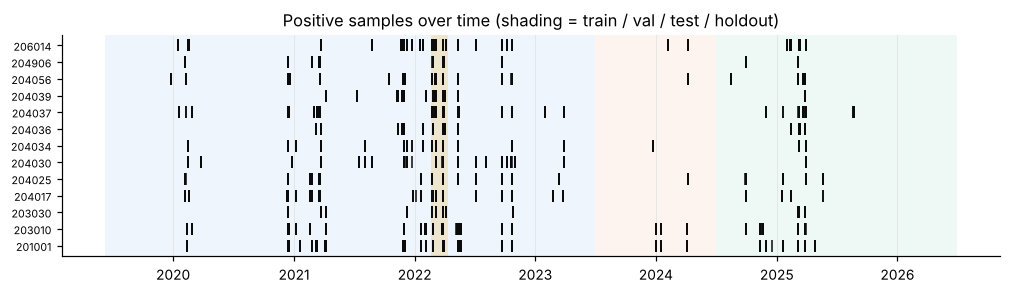

In [23]:
fig, ax = plt.subplots(figsize=(11, 2.6))
pos = samples[samples.label == 1]
shade_splits(ax)
for i, (c, g) in enumerate(pos.groupby('catchment_id')):
    ax.plot(g.issue_utc, np.full(len(g), i), '|', ms=8, color='#0b0b0b')
ax.set_yticks(range(pos.catchment_id.nunique()), sorted(pos.catchment_id.unique()), fontsize=7)
ax.set_title('Positive samples over time (shading = train / val / test / holdout)'); ax.grid(axis='y', visible=False)
plt.show()

**What it shows.**
- Every positive sample (black tick) over time, per catchment, on top of the split periods.

**What it means.**
- Positives come in bursts that match the wet periods.
- **The test period is dominated by one season:** 214 of 299 test positives fall in January–March 2025, which includes the ex-Tropical Cyclone Alfred rain of early March 2025.

**Issues and limits.**
- A single storm can decide which candidate looks best on the test set. A model good at tropical-cyclone rain would win even if it is worse elsewhere.

**Action.**
Report test results per event or per season as well as overall, and show the number of events behind each score.

## 8. Candidate B windows

`WindowDataset` cuts each 72-h window from `data/processed/b/dynamic_hourly.parquet` on demand.

564708 windows | dynamic: ['rain_mean', 'rain_max', 'rain_p90', 'rain_frac_heavy', 'soil_upper_mm', 'soil_lower_mm'] | static: 13


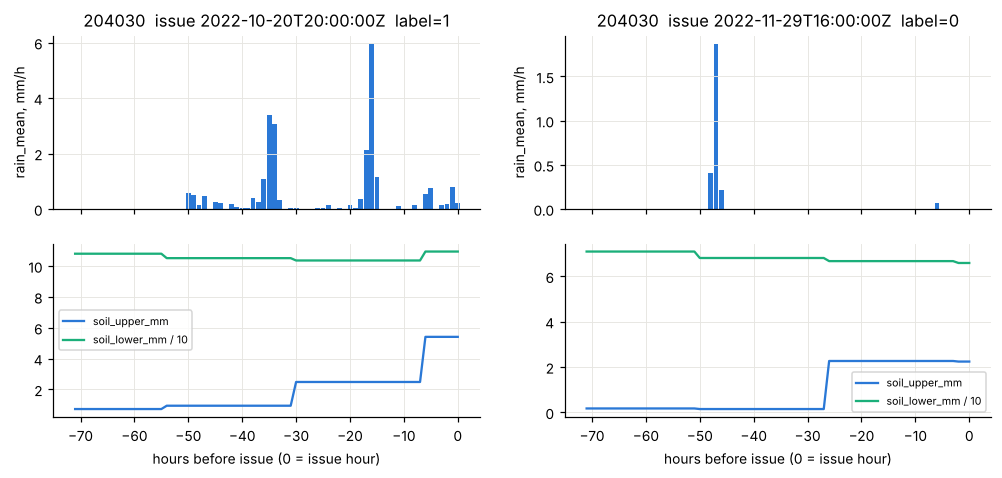

In [24]:
from b_dataset import WindowDataset
ds = WindowDataset()
print(len(ds), 'windows | dynamic:', ds.dyn_names, '| static:', len(ds.static_names))
ip = int(np.flatnonzero(ds.samples.label.values == 1)[len(np.flatnonzero(ds.samples.label.values == 1)) // 2])
ineg = int(np.flatnonzero(ds.samples.label.values == 0)[ip])
fig, axes = plt.subplots(2, 2, figsize=(11, 4.5), sharex=True)
for col, i in enumerate((ip, ineg)):
    x, xs, y = ds[i]; s = ds.samples.iloc[i]; h = np.arange(-71, 1)
    axes[0, col].bar(h, x[:, 0], color=BLUE, width=0.9); axes[0, col].set_ylabel('rain_mean, mm/h')
    axes[0, col].set_title(f'{s.catchment_id}  issue {s.issue_utc}  label={int(y)}')
    axes[1, col].plot(h, x[:, 4], color=BLUE, label='soil_upper_mm'); axes[1, col].plot(h, x[:, 5] / 10, color=AQUA, label='soil_lower_mm / 10')
    axes[1, col].set_xlabel('hours before issue (0 = issue hour)'); axes[1, col].legend(fontsize=7)
plt.show()

**What it shows.**
- Two of B's input windows:
  - left: a positive sample (flood within 6 h);
  - right: a negative one.
- Each shows 72 hourly steps ending at the issue hour (0): catchment-mean rain (top) and the two soil layers (bottom; lower layer divided by 10 to share the axis).

**What it means.**
- **Positive example:** two rain bursts in the last 36 h and wetter upper soil, before a crossing of a low (1.21 m) threshold.
- **Negative example:** one small burst two days earlier and little since.
- This is the information an LSTM uses: how much rain fell, when it fell, and how wet the soil was.

**Issues and limits.**
- **Rain is zero-inflated.** Most hours are 0, and a few are large.
  - A standard z-score turns the zeros into negative values and lets rare peaks dominate.
  - Use `log1p` (or divide by a fixed scale) and keep 0 at 0.
- **Soil is a step function**, because AWRA-L is daily.

In [25]:
# Distribution shift check across splits (dynamic features at the issue hour)
dyn = pd.read_parquet(D / 'processed' / 'b' / 'dynamic_hourly.parquet')
dyn['split'] = split_of(pd.DatetimeIndex(dyn.hour_end_utc))
rows = []
for sp, g in dyn[dyn.split != ''].groupby('split'):
    rows.append({'split': sp, 'rain>0 %': round(100 * (g.rain_mean > 0).mean(), 1),
                 'rain p99 mm/h': round(g.rain_mean.quantile(0.99), 2), 'rain max mm/h': round(g.rain_mean.max(), 1),
                 'soil_upper median': round(g.soil_upper_mm.median(), 1), 'soil_lower median': round(g.soil_lower_mm.median(), 1)})
pd.DataFrame(rows)

,split,rain>0 %,rain p99 mm/h,rain max mm/h,soil_upper median,soil_lower median
0,holdout,43.7,8.96,25.0,3.9,168.5
1,test,26.7,3.60,35.8,1.4,112.0
2,train,20.0,3.19,36.0,1.2,103.0
3,val,23.6,3.17,24.6,1.3,84.0


**What it shows.**
- For each split, at the issue hour: share of hours with rain, 99th-percentile and maximum rain, and median soil water.

**What it means.**
- **Train, validation and test are similar:**
  - rain in 20–27% of hours;
  - 99th-percentile rain 3.2–3.6 mm/h;
  - similar soil.
- So the chronological split does not create a large shift: a model trained on 2019–2023 faces similar conditions in 2024–2026.
- **The holdout is very different on purpose:** rain in 44% of hours, a 99th percentile of 9 mm/h, and lower soil near full (168 mm). It tests behaviour beyond typical conditions.

**Issues and limits.**
- Similar averages do not guarantee similar extremes. The test set's largest storms (early 2025) may still exceed anything in training at some catchments.

## 9. Automatic checks

In [26]:
results = []
def check(name, ok, detail=''):
    results.append({'check': name, 'result': 'PASS' if ok else 'FAIL', 'detail': detail})

# 1 every sample sits inside its split and the split matches the config
sp = split_of(pd.DatetimeIndex(samples.issue_utc))
check('split column matches config dates', (sp == samples.split.values).all())

# 2 gap: no non-holdout sample within gap_hours of a split change
gap = CFG['split']['gap_hours']; it = pd.date_range(P0, P1, freq='1h', tz='UTC'); spl = split_of(it)
chg = it[1:][spl[1:] != spl[:-1]]
d = np.min(np.abs((samples.issue_utc.values[:, None] - chg.values[None, :]) / np.timedelta64(1, 'h')), axis=1)
check(f'no non-holdout sample within {gap} h of a split change', ((d >= gap) | (samples.split == 'holdout')).all(), f'min distance {d[samples.split != "holdout"].min():.0f} h')

# 3 labels agree with events.csv
lab = np.zeros(len(samples), int)
for e in ev.itertuples():
    m = (samples.catchment_id == e.catchment_id) & (samples.issue_utc >= e.onset_utc - pd.Timedelta(hours=6)) & (samples.issue_utc < e.onset_utc)
    lab[m.values] = 1
check('labels recomputed from events.csv match', (lab == samples.label.values).all(), f'{int((lab != samples.label.values).sum())} differences')

# 4 no sample while already in flood
inf = np.zeros(len(samples), bool)
for e in ev.itertuples():
    inf |= ((samples.catchment_id == e.catchment_id) & (samples.issue_utc >= e.onset_utc) & (samples.issue_utc < e.end_utc)).values
check('no sample issued while already in flood', not inf.any(), f'{inf.sum()} rows')

# 5 window end == issue time (no future input) on a random subset
rng = np.random.default_rng(0); idx = rng.choice(len(ds), 2000, replace=False)
ends = np.array([ds.t0[ds.samples.catchment_id[i]] + pd.Timedelta(hours=int(ds.end_idx[i])) for i in idx])
check('last input hour equals issue time (2,000 random rows)', (pd.DatetimeIndex(ends) == pd.DatetimeIndex(pd.to_datetime(ds.samples.issue_utc.iloc[idx], utc=True))).all())

# 6 thresholds come from train years only
thr_ok = []
for c in cat.itertuples():
    s = lv[c.catchment_id]; tr = s[split_of(s.index) == 'train'].dropna()
    thr_ok.append(abs(np.percentile(tr, CFG['label']['fallback_percentile']) - float(c.threshold_m)) < 1e-3)
check('fallback thresholds = p99 of train-years level', all(thr_ok))

# 7 no NaN in any window (rolling check)
bad = 0
for c, arr in ds.series.items():
    f = pd.Series(np.isnan(arr).any(1)).rolling(ds.hist, min_periods=1).max().values > 0
    bad += int(f[ds.end_idx[(ds.samples.catchment_id == c).values]].sum())
check('no missing values inside any 72-h window', bad == 0, f'{bad} windows')

pd.DataFrame(results)

,check,result,detail
0,split column matches config dates,PASS,
1,no non-holdout sample within 78 h of a split c...,PASS,min distance 78 h
2,labels recomputed from events.csv match,PASS,0 differences
3,no sample issued while already in flood,PASS,0 rows
4,"last input hour equals issue time (2,000 rando...",PASS,
5,fallback thresholds = p99 of train-years level,PASS,
6,no missing values inside any 72-h window,PASS,0 windows


**What it shows.**
- Seven automatic checks on the final data. All pass.

**What it means.**
- The split follows the configured dates, with 78 h gaps.
- Labels match `events.csv` exactly.
- No sample is issued while the river is already in flood.
- The last input hour equals the issue time, so no future information is used.
- Thresholds use training years only.
- No 72 h window contains a missing value.
- These are the conditions for a fair, leak-free evaluation.

**Issues and limits.**
- The checks confirm the pipeline did what it was told. They do not confirm that the inputs are physically right: that is what the plausibility review above is for.

**Action.**
Before training:
1. Review the two suspected radar artefacts (204056 Jul 2024, 204037 Apr 2024).
2. Decide on 3-of-4-scan hours.
3. Add official minor flood levels where available.
4. Decide how to handle the thin validation year.
5. Agree the tile size with member A.